# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Data Processing and Linear Regression Exploration
*By Mark Lambert - C00192497*

---

In third year I built and deployed a LastFm scrobbling program, which familiarised me with the LastFM API. 

I decided for my Data Science & Machine Learning Portfolio that usming this data would be interesting and applicable.
        
The first step is to connect with the API using an API key, and then pull all of the scrobbles using the ```User.getRecentTracks``` header.

```%pip install pandas scikit-learn matplotlib```

In [ ]:
%pip install pandas scikit-learn matplotlib

In [3]:
import requests
import pandas as pd
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import make_pipeline

API_KEY = ' api key'
USERNAME = ' username'

all_tracks = []
page = 1
total_pages = 1

while page <= total_pages:
    response = requests.get('http://ws.audioscrobbler.com/2.0/', params={
        'method': 'user.getrecenttracks',
        'user': USERNAME,
        'api_key': API_KEY,
        'format': 'json',
        'limit': 200,
        'page': page
    })
    data = response.json()
    if page == 1:
        total_pages = int(data['recenttracks']['@attr']['totalPages'])
    all_tracks.extend(data['recenttracks']['track'])
    page += 1

The data's raw columns.

The ones that this portfolio will focus on are **artist, album, name and date**. ```@attr``` holds songs that are marked ```nowplaying = true```. 

As such, anything with this attribute will also be ignored later on.

In [4]:
scrobblesResponse = pd.DataFrame(all_tracks)

scrobblesResponse.columns

Index(['artist', 'streamable', 'image', 'mbid', 'album', 'name', '@attr',
       'url', 'date'],
      dtype='str')

The raw data shows that the actual readable details for each artist, album are hashed, but there is an embedded ```#text``` feature within each hash which must be extracted

In [5]:
scrobblesResponse

,artist,streamable,image,mbid,album,name,@attr,url,date
0,{'mbid': '83d91898-7763-47d7-b03b-b92132375c47...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",37a3f68f-1460-4c48-bc9b-1426dbf6bf84,"{'mbid': '', '#text': 'The Wall - Disc 2'}",Vera,{'nowplaying': 'true'},https://www.last.fm/music/Pink+Floyd/_/Vera,NaN
1,{'mbid': '83d91898-7763-47d7-b03b-b92132375c47...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",102f0fa0-f77d-4db1-8503-849486a8c57e,"{'mbid': '', '#text': 'The Wall - Disc 2'}",Nobody Home,NaN,https://www.last.fm/music/Pink+Floyd/_/Nobody+...,"{'uts': '1791918107', '#text': '13 Oct 2026, 1..."
2,{'mbid': '83d91898-7763-47d7-b03b-b92132375c47...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",ae7ad815-a08f-4fbe-998d-8fa1a9f9837f,"{'mbid': '', '#text': 'The Wall - Disc 2'}",Is There Anybody Out There?,NaN,https://www.last.fm/music/Pink+Floyd/_/Is+Ther...,"{'uts': '1791917902', '#text': '13 Oct 2026, 1..."
3,{'mbid': '83d91898-7763-47d7-b03b-b92132375c47...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",,"{'mbid': '', '#text': 'The Wall - Disc 2'}",Hey You,NaN,https://www.last.fm/music/Pink+Floyd/_/Hey+You,"{'uts': '1791917741', '#text': '13 Oct 2026, 1..."
4,{'mbid': '83d91898-7763-47d7-b03b-b92132375c47...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",4e015e49-ce00-4ab3-b7b2-0a1cb2edf8a0,"{'mbid': '', '#text': 'The Wall - Disc 1'}",Goodbye Cruel World,NaN,https://www.last.fm/music/Pink+Floyd/_/Goodbye...,"{'uts': '1791917459', '#text': '13 Oct 2026, 1..."
...,...,...,...,...,...,...,...,...,...
18020,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",362c85ba-c79b-478e-8321-0383c3ac8101,{'mbid': '0d2cb66c-3a32-4f81-b977-9231c461c34a...,Why Won't They Talk to Me?,NaN,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,"{'uts': '1763463648', '#text': '18 Nov 2025, 1..."
18021,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",6f93589f-4a47-4a9d-9274-09a0f437ad15,{'mbid': '10ac58ca-0655-4b16-a6cb-58fdc309de0a...,Over,NaN,https://www.last.fm/music/Portishead/_/Over,"{'uts': '1763463370', '#text': '18 Nov 2025, 1..."
18022,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",6da0b598-d9cf-4f62-8376-bc3181e509af,{'mbid': '51f8289e-7379-4c7b-ab50-564e2f875594...,Obsolete,NaN,https://www.last.fm/music/Tame+Impala/_/Obsolete,"{'uts': '1763462844', '#text': '18 Nov 2025, 1..."
18023,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",ad79b526-8df8-4e79-8756-0607df153e59,{'mbid': '51f8289e-7379-4c7b-ab50-564e2f875594...,Piece Of Heaven,NaN,https://www.last.fm/music/Tame+Impala/_/Piece+...,"{'uts': '1763462559', '#text': '18 Nov 2025, 1..."


Next, as per [Carlos Medina's article](https://medium.com/hemisferios/using-the-last-fm-api-to-extract-data-and-analyzing-it-with-python-part-1-ffe96f812455), first we must select the colums of interest and, as the column name is obscure I have chosen to rename it to **song**

In [6]:
scrobbles = scrobblesResponse

scrobbles = scrobbles[['artist', 'album', 'name', 'url', 'date']]
scrobbles.rename(columns={'name': 'song'}, inplace=True)
scrobbles

,artist,album,song,url,date
0,{'mbid': '83d91898-7763-47d7-b03b-b92132375c47...,"{'mbid': '', '#text': 'The Wall - Disc 2'}",Vera,https://www.last.fm/music/Pink+Floyd/_/Vera,NaN
1,{'mbid': '83d91898-7763-47d7-b03b-b92132375c47...,"{'mbid': '', '#text': 'The Wall - Disc 2'}",Nobody Home,https://www.last.fm/music/Pink+Floyd/_/Nobody+...,"{'uts': '1791918107', '#text': '13 Oct 2026, 1..."
2,{'mbid': '83d91898-7763-47d7-b03b-b92132375c47...,"{'mbid': '', '#text': 'The Wall - Disc 2'}",Is There Anybody Out There?,https://www.last.fm/music/Pink+Floyd/_/Is+Ther...,"{'uts': '1791917902', '#text': '13 Oct 2026, 1..."
3,{'mbid': '83d91898-7763-47d7-b03b-b92132375c47...,"{'mbid': '', '#text': 'The Wall - Disc 2'}",Hey You,https://www.last.fm/music/Pink+Floyd/_/Hey+You,"{'uts': '1791917741', '#text': '13 Oct 2026, 1..."
4,{'mbid': '83d91898-7763-47d7-b03b-b92132375c47...,"{'mbid': '', '#text': 'The Wall - Disc 1'}",Goodbye Cruel World,https://www.last.fm/music/Pink+Floyd/_/Goodbye...,"{'uts': '1791917459', '#text': '13 Oct 2026, 1..."
...,...,...,...,...,...
18020,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,{'mbid': '0d2cb66c-3a32-4f81-b977-9231c461c34a...,Why Won't They Talk to Me?,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,"{'uts': '1763463648', '#text': '18 Nov 2025, 1..."
18021,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,{'mbid': '10ac58ca-0655-4b16-a6cb-58fdc309de0a...,Over,https://www.last.fm/music/Portishead/_/Over,"{'uts': '1763463370', '#text': '18 Nov 2025, 1..."
18022,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,{'mbid': '51f8289e-7379-4c7b-ab50-564e2f875594...,Obsolete,https://www.last.fm/music/Tame+Impala/_/Obsolete,"{'uts': '1763462844', '#text': '18 Nov 2025, 1..."
18023,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,{'mbid': '51f8289e-7379-4c7b-ab50-564e2f875594...,Piece Of Heaven,https://www.last.fm/music/Tame+Impala/_/Piece+...,"{'uts': '1763462559', '#text': '18 Nov 2025, 1..."


Next, convert the ```artist, album``` and ```datess``` to strings

In [7]:
scrobbles['artist'] = scrobbles['artist'].astype(str)
scrobbles['album'] = scrobbles['album'].astype(str)
scrobbles['date'] = scrobbles['date'].astype(str)

Extract the embedded ```#text``` attribute from each of the ```artist, album``` and ```date``` fields

In [8]:
scrobbles[['mbid2','artist']]=scrobbles['artist'].str.split("#text':", n = 1, expand = True)
scrobbles= scrobbles.drop('mbid2', axis=1)
scrobbles[['mbid3','album']]=scrobbles['album'].str.split("#text':", n = 1, expand = True)
scrobbles= scrobbles.drop('mbid3', axis=1)
scrobbles[['uts','date']]=scrobbles['date'].str.split("#text':", n = 1, expand = True)
scrobbles.head()

,artist,album,song,url,date,uts
0,'Pink Floyd'},'The Wall - Disc 2'},Vera,https://www.last.fm/music/Pink+Floyd/_/Vera,NaN,NaN
1,'Pink Floyd'},'The Wall - Disc 2'},Nobody Home,https://www.last.fm/music/Pink+Floyd/_/Nobody+...,"'13 Oct 2026, 19:01'}","{'uts': '1791918107', '"
2,'Pink Floyd'},'The Wall - Disc 2'},Is There Anybody Out There?,https://www.last.fm/music/Pink+Floyd/_/Is+Ther...,"'13 Oct 2026, 18:58'}","{'uts': '1791917902', '"
3,'Pink Floyd'},'The Wall - Disc 2'},Hey You,https://www.last.fm/music/Pink+Floyd/_/Hey+You,"'13 Oct 2026, 18:55'}","{'uts': '1791917741', '"
4,'Pink Floyd'},'The Wall - Disc 1'},Goodbye Cruel World,https://www.last.fm/music/Pink+Floyd/_/Goodbye...,"'13 Oct 2026, 18:50'}","{'uts': '1791917459', '"


Removing the ```}``` and ```'``` characters from the ```artist and album``` entries

In [9]:
scrobbles['artist'] = scrobbles['artist'].str.strip("}'\" ")
scrobbles['album'] = scrobbles['album'].str.strip("}'\" ")
scrobbles.head()

,artist,album,song,url,date,uts
0,Pink Floyd,The Wall - Disc 2,Vera,https://www.last.fm/music/Pink+Floyd/_/Vera,NaN,NaN
1,Pink Floyd,The Wall - Disc 2,Nobody Home,https://www.last.fm/music/Pink+Floyd/_/Nobody+...,"'13 Oct 2026, 19:01'}","{'uts': '1791918107', '"
2,Pink Floyd,The Wall - Disc 2,Is There Anybody Out There?,https://www.last.fm/music/Pink+Floyd/_/Is+Ther...,"'13 Oct 2026, 18:58'}","{'uts': '1791917902', '"
3,Pink Floyd,The Wall - Disc 2,Hey You,https://www.last.fm/music/Pink+Floyd/_/Hey+You,"'13 Oct 2026, 18:55'}","{'uts': '1791917741', '"
4,Pink Floyd,The Wall - Disc 1,Goodbye Cruel World,https://www.last.fm/music/Pink+Floyd/_/Goodbye...,"'13 Oct 2026, 18:50'}","{'uts': '1791917459', '"


The ```date and uts``` fields also need to be stripped of the remaining dirty characters. I have also chosen to rename uts to **timestamp** as it is more descriptive.

In [10]:
scrobbles['date'] = scrobbles['date'].str.strip("}'\" ")
scrobbles['uts'] = scrobbles['uts'].str.strip("{uts':','\" ")
scrobbles.rename(columns={'uts': 'timestamp'}, inplace=True)
scrobbles.head()

,artist,album,song,url,date,timestamp
0,Pink Floyd,The Wall - Disc 2,Vera,https://www.last.fm/music/Pink+Floyd/_/Vera,NaN,NaN
1,Pink Floyd,The Wall - Disc 2,Nobody Home,https://www.last.fm/music/Pink+Floyd/_/Nobody+...,"13 Oct 2026, 19:01",1791918107
2,Pink Floyd,The Wall - Disc 2,Is There Anybody Out There?,https://www.last.fm/music/Pink+Floyd/_/Is+Ther...,"13 Oct 2026, 18:58",1791917902
3,Pink Floyd,The Wall - Disc 2,Hey You,https://www.last.fm/music/Pink+Floyd/_/Hey+You,"13 Oct 2026, 18:55",1791917741
4,Pink Floyd,The Wall - Disc 1,Goodbye Cruel World,https://www.last.fm/music/Pink+Floyd/_/Goodbye...,"13 Oct 2026, 18:50",1791917459


Next, the date field must be converted into a date only field

In [11]:
scrobbles['date'] = pd.to_datetime(scrobbles['date'], unit='s')
scrobbles['date_only'] = scrobbles['date'].dt.date
scrobbles

,artist,album,song,url,date,timestamp,date_only
0,Pink Floyd,The Wall - Disc 2,Vera,https://www.last.fm/music/Pink+Floyd/_/Vera,NaT,NaN,NaT
1,Pink Floyd,The Wall - Disc 2,Nobody Home,https://www.last.fm/music/Pink+Floyd/_/Nobody+...,2026-10-13 19:01:00,1791918107,2026-10-13
2,Pink Floyd,The Wall - Disc 2,Is There Anybody Out There?,https://www.last.fm/music/Pink+Floyd/_/Is+Ther...,2026-10-13 18:58:00,1791917902,2026-10-13
3,Pink Floyd,The Wall - Disc 2,Hey You,https://www.last.fm/music/Pink+Floyd/_/Hey+You,2026-10-13 18:55:00,1791917741,2026-10-13
4,Pink Floyd,The Wall - Disc 1,Goodbye Cruel World,https://www.last.fm/music/Pink+Floyd/_/Goodbye...,2026-10-13 18:50:00,1791917459,2026-10-13
...,...,...,...,...,...,...,...
18020,Tame Impala,Lonerism,Why Won't They Talk to Me?,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,2025-11-18 11:00:00,1763463648,2025-11-18
18021,Portishead,Portishead,Over,https://www.last.fm/music/Portishead/_/Over,2025-11-18 10:56:00,1763463370,2025-11-18
18022,Tame Impala,Deadbeat,Obsolete,https://www.last.fm/music/Tame+Impala/_/Obsolete,2025-11-18 10:47:00,1763462844,2025-11-18
18023,Tame Impala,Deadbeat,Piece Of Heaven,https://www.last.fm/music/Tame+Impala/_/Piece+...,2025-11-18 10:42:00,1763462559,2025-11-18


Finally, the row which contains NaN must be removed, as this was a song that had the ```@attr``` of ```nowplaying = true```, so it should not count as a fully scrobbled song

In [12]:
scrobbles = scrobbles.dropna(subset=['date'])

def time_of_day(hour):
    if hour >= 22 or hour < 5:
        return 'night'
    if hour < 12:
        return 'morning'
    if hour < 17:
        return 'afternoon'
    return 'evening'

local_time = scrobbles['date'].dt.tz_localize('UTC').dt.tz_convert('Europe/Dublin')
scrobbles['hour'] = local_time.dt.hour
scrobbles['tod'] = scrobbles['hour'].apply(time_of_day)
scrobbles['month'] = scrobbles['date'].dt.to_period('M')
scrobbles.head()

,artist,album,song,url,date,timestamp,date_only,hour,tod,month
1,Pink Floyd,The Wall - Disc 2,Nobody Home,https://www.last.fm/music/Pink+Floyd/_/Nobody+...,2026-10-13 19:01:00,1791918107,2026-10-13,20,evening,2026-10
2,Pink Floyd,The Wall - Disc 2,Is There Anybody Out There?,https://www.last.fm/music/Pink+Floyd/_/Is+Ther...,2026-10-13 18:58:00,1791917902,2026-10-13,19,evening,2026-10
3,Pink Floyd,The Wall - Disc 2,Hey You,https://www.last.fm/music/Pink+Floyd/_/Hey+You,2026-10-13 18:55:00,1791917741,2026-10-13,19,evening,2026-10
4,Pink Floyd,The Wall - Disc 1,Goodbye Cruel World,https://www.last.fm/music/Pink+Floyd/_/Goodbye...,2026-10-13 18:50:00,1791917459,2026-10-13,19,evening,2026-10
5,Pink Floyd,The Wall - Disc 1,Another Brick in the Wall Part 3,https://www.last.fm/music/Pink+Floyd/_/Another...,2026-10-13 18:49:00,1791917382,2026-10-13,19,evening,2026-10


In [13]:
top_artists = scrobbles['artist'].value_counts().head(10).index
subset = scrobbles[scrobbles['artist'].isin(top_artists)].copy()

print(subset['artist'].value_counts())
print(pd.crosstab(subset['tod'], subset['artist'], normalize='index').round(2))

artist
Arctic Monkeys           2229
Tame Impala              2040
Red Hot Chili Peppers    1553
Portishead               1188
Alice in Chains          1106
John Mayer                892
Morcheeba                 562
Ghost                     559
Massive Attack            500
Pink Floyd                499
Name: count, dtype: int64
artist     Alice in Chains  Arctic Monkeys  Ghost  John Mayer  Massive Attack  \
tod                                                                             
afternoon             0.10            0.19   0.07        0.08            0.05   
evening               0.09            0.23   0.02        0.10            0.04   
morning               0.12            0.11   0.11        0.02            0.08   
night                 0.06            0.27   0.00        0.14            0.02   

artist     Morcheeba  Pink Floyd  Portishead  Red Hot Chili Peppers  \
tod                                                                   
afternoon       0.03        0.04      

In [14]:
X = pd.get_dummies(subset['tod']).astype(int)
y = subset['artist']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

baseline = y_train.value_counts().idxmax()
print('Baseline accuracy:', accuracy_score(y_test, [baseline] * len(y_test)))
print('Model accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Baseline accuracy: 0.20035938903863432
Model accuracy: 0.2389937106918239
                       precision    recall  f1-score   support

      Alice in Chains       0.00      0.00      0.00       221
       Arctic Monkeys       0.23      0.57      0.33       446
                Ghost       0.00      0.00      0.00       112
           John Mayer       0.00      0.00      0.00       178
       Massive Attack       0.00      0.00      0.00       100
            Morcheeba       0.00      0.00      0.00       112
           Pink Floyd       0.00      0.00      0.00       100
           Portishead       0.00      0.00      0.00       238
Red Hot Chili Peppers       0.00      0.00      0.00       311
          Tame Impala       0.24      0.68      0.36       408

             accuracy                           0.24      2226
            macro avg       0.05      0.13      0.07      2226
         weighted avg       0.09      0.24      0.13      2226



           Alice in Chains  Arctic Monkeys  Ghost  John Mayer  Massive Attack  \
morning               0.12            0.11   0.11        0.02            0.07   
afternoon             0.10            0.19   0.07        0.07            0.05   
evening               0.09            0.23   0.02        0.10            0.04   
night                 0.06            0.27   0.01        0.14            0.02   

           Morcheeba  Pink Floyd  Portishead  Red Hot Chili Peppers  \
morning         0.05        0.01        0.09                   0.11   
afternoon       0.03        0.04        0.08                   0.16   
evening         0.06        0.06        0.13                   0.14   
night           0.09        0.08        0.13                   0.04   

           Tame Impala  
morning           0.30  
afternoon         0.21  
evening           0.13  
night             0.17  


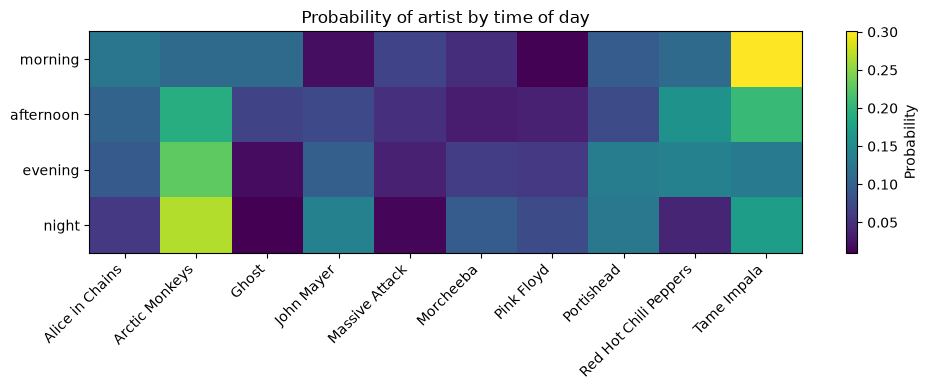

In [15]:
buckets = pd.DataFrame(np.eye(len(X.columns), dtype=int), columns=X.columns, index=X.columns)
probs = pd.DataFrame(clf.predict_proba(buckets), columns=clf.classes_, index=buckets.index)
probs = probs.reindex(['morning', 'afternoon', 'evening', 'night'])
print(probs.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(probs.values, aspect='auto')
ax.set_xticks(range(len(probs.columns)))
ax.set_xticklabels(probs.columns, rotation=45, ha='right')
ax.set_yticks(range(len(probs.index)))
ax.set_yticklabels(probs.index)
fig.colorbar(im, label='Probability')
ax.set_title('Probability of artist by time of day')
plt.tight_layout()
plt.show()

Filter the data further into daily scrobbles

In [16]:
daily = scrobbles.groupby('date_only').size().reset_index(name='scrobble_count')
daily['date_only'] = pd.to_datetime(daily['date_only'])
daily.set_index('date_only', inplace=True)

In [17]:
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
for i in range(7):
    daily[days[i]] = (daily.index.dayofweek == i).astype(float)

In [18]:
monthly = scrobbles.groupby('month').size().reset_index(name='scrobble_count')
monthly

,month,scrobble_count
0,2025-11,1254
1,2025-12,1732
2,2026-01,1692
3,2026-02,1345
4,2026-03,1022
5,2026-04,522
6,2026-05,829
7,2026-06,1942
8,2026-07,2479
9,2026-08,2430


Final part of the LastFm API interaction, I now output the data to csv's so that I don't have to request the data each time I run the program

In [19]:
scrobbles.to_csv('datasets/scrobbles.csv', index=False)

In [20]:
daily.to_csv('datasets/daily.csv', index=True)

Initial linear regression doesn't fit quite so well

C:\Users\markl\pipx\venvs\jupyterlab\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


Text(0, 0.5, 'Scrobbles per Day')

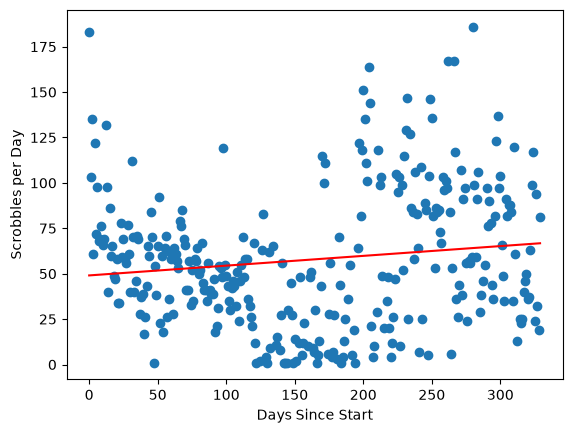

In [21]:
daily['days_since_start'] = (daily.index - daily.index[0]).days

X = daily[['days_since_start']]
y = daily['scrobble_count']

model = LinearRegression(fit_intercept=True)
model.fit(X, y)

xfit = np.linspace(X.min().iloc[0], X.max().iloc[0], 1000)
yfit = model.predict(xfit[:, np.newaxis])

plt.scatter(X, y)
plt.plot(xfit, yfit, color='red')
plt.xlabel('Days Since Start')
plt.ylabel('Scrobbles per Day')

Polynomial w/ a degree of 2 fits better

C:\Users\markl\pipx\venvs\jupyterlab\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


Text(0, 0.5, 'Scrobbles per Day')

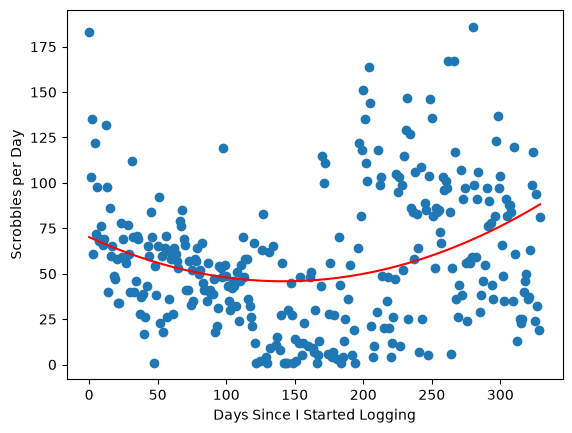

In [22]:
daily["days_since_start"] = (daily.index - daily.index[0]).days

X = daily[["days_since_start"]]
y = daily["scrobble_count"]

poly_model = make_pipeline(PolynomialFeatures(2), LinearRegression())

poly_model.fit(X, y)

xfit = np.linspace(X.min().iloc[0], X.max().iloc[0], 1000)
yfit = poly_model.predict(xfit[:, np.newaxis])

plt.scatter(X, y)  
plt.plot(xfit, yfit, color="red")
plt.xlabel("Days Since I Started Logging")
plt.ylabel("Scrobbles per Day")

Using the [unofficial docs](https://lastfm-docs.github.io/api-docs/user/getLovedTracks/#examples) once again, the data can be combined with the ```User.getLovedTracks``` header. A new boolean field called ```is_loved``` can be joined to the full scrobble dataset

In [23]:
all_loved_tracks = []
loved_page = 1
total_loved_pages = 1

while loved_page <= total_loved_pages:
    response = requests.get('http://ws.audioscrobbler.com/2.0/', params={
        'method': 'user.getlovedtracks',
        'user': USERNAME,
        'api_key': API_KEY,
        'format': 'json',
        'limit': 200,
        'page': loved_page
    })
    data = response.json()
    if loved_page == 1:
        total_loved_pages = int(data['lovedtracks']['@attr']['totalPages'])
    tracks = data['lovedtracks']['track']
    for track in tracks:
        all_loved_tracks.append({
            'artist': track['artist']['name'],
            'track': track['name'],
            'timestamp': int(track['date']['uts']) if 'date' in track else None
        })
    loved_page += 1

In [24]:
lovedScrobbles = pd.DataFrame(all_loved_tracks)
lovedScrobbles['is_loved'] = 1
lovedScrobbles = lovedScrobbles.drop_duplicates(subset=['artist', 'track'])

df_merged = pd.merge(
    scrobbles,
    lovedScrobbles[['artist', 'track', 'is_loved']],
    left_on=['artist', 'song'],
    right_on=['artist', 'track'],
    how='left'
)

loved = df_merged.drop(columns=['track'])
loved['is_loved'] = loved['is_loved'].fillna(0).astype(int)
loved

,artist,album,song,url,date,timestamp,date_only,hour,tod,month,is_loved
0,Pink Floyd,The Wall - Disc 2,Nobody Home,https://www.last.fm/music/Pink+Floyd/_/Nobody+...,2026-10-13 19:01:00,1791918107,2026-10-13,20,evening,2026-10,0
1,Pink Floyd,The Wall - Disc 2,Is There Anybody Out There?,https://www.last.fm/music/Pink+Floyd/_/Is+Ther...,2026-10-13 18:58:00,1791917902,2026-10-13,19,evening,2026-10,0
2,Pink Floyd,The Wall - Disc 2,Hey You,https://www.last.fm/music/Pink+Floyd/_/Hey+You,2026-10-13 18:55:00,1791917741,2026-10-13,19,evening,2026-10,0
3,Pink Floyd,The Wall - Disc 1,Goodbye Cruel World,https://www.last.fm/music/Pink+Floyd/_/Goodbye...,2026-10-13 18:50:00,1791917459,2026-10-13,19,evening,2026-10,0
4,Pink Floyd,The Wall - Disc 1,Another Brick in the Wall Part 3,https://www.last.fm/music/Pink+Floyd/_/Another...,2026-10-13 18:49:00,1791917382,2026-10-13,19,evening,2026-10,0
...,...,...,...,...,...,...,...,...,...,...,...
17930,Tame Impala,Lonerism,Why Won't They Talk to Me?,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,2025-11-18 11:00:00,1763463648,2025-11-18,11,morning,2025-11,1
17931,Portishead,Portishead,Over,https://www.last.fm/music/Portishead/_/Over,2025-11-18 10:56:00,1763463370,2025-11-18,10,morning,2025-11,1
17932,Tame Impala,Deadbeat,Obsolete,https://www.last.fm/music/Tame+Impala/_/Obsolete,2025-11-18 10:47:00,1763462844,2025-11-18,10,morning,2025-11,1
17933,Tame Impala,Deadbeat,Piece Of Heaven,https://www.last.fm/music/Tame+Impala/_/Piece+...,2025-11-18 10:42:00,1763462559,2025-11-18,10,morning,2025-11,0


In [25]:
loved.to_csv('datasets/loved.csv', index=False)

In [26]:
spotify = pd.read_csv('datasets/spotify.csv')

In [27]:
spotify['clean_artist'] = spotify['artists'].str.lower().str.strip()
spotify['clean_track'] = spotify['track_name'].str.lower().str.strip()

loved['clean_artist'] = loved['artist'].str.lower().str.strip()
loved['clean_track'] = loved['song'].str.lower().str.strip()

spotify_unique = spotify.drop_duplicates(subset=['clean_artist', 'clean_track'])

merged = pd.merge(
    loved,
    spotify_unique,
    on=['clean_artist', 'clean_track'],
    how='left',
    indicator=True
)

matched_count = (merged['_merge'] == 'both').sum()
total_count = len(loved)
match_rate = (matched_count / total_count) * 100

print(f"{matched_count} of {total_count} tracks match ({match_rate:.2f}%)")

6285 of 17935 tracks match (35.04%)


In [28]:
scrobble_counts = merged.groupby(['clean_artist', 'clean_track']).size().reset_index(name='play_count')

track_features = merged.drop_duplicates(subset=['clean_artist', 'clean_track']).copy()
track_features['play_count'] = track_features.groupby(['clean_artist', 'clean_track'])['clean_track'].transform('count') 

In [35]:
audio_cols = ['danceability', 'energy', 'valence', 'acousticness', 'instrumentalness', 'tempo', 'speechiness']

aggregated = merged.groupby(['clean_artist', 'clean_track'])[audio_cols].first().reset_index()
aggregated['play_count'] = merged.groupby(['clean_artist', 'clean_track'])['is_loved'].size().values
aggregated['is_loved'] = loved['is_loved']
aggregated = aggregated.dropna(subset=['danceability', 'energy', 'valence'])
aggregated.to_csv('datasets/aggregatedData.csv', index=False)
aggregated

,clean_artist,clean_track,danceability,energy,valence,acousticness,instrumentalness,tempo,speechiness,play_count,is_loved
4,a família,brinquedo assassino,0.771,0.746,0.502,0.090200,0.000000,148.054,0.2620,2,0
13,abba,super trouper,0.724,0.724,0.927,0.294000,0.000000,117.986,0.0304,1,0
14,adnan sami,tera chehra,0.646,0.562,0.488,0.523000,0.002100,100.000,0.0331,1,0
20,air,kelly watch the stars,0.516,0.743,0.226,0.282000,0.637000,109.837,0.0292,17,0
21,air,la femme d'argent,0.517,0.737,0.558,0.434000,0.684000,79.820,0.0352,20,0
...,...,...,...,...,...,...,...,...,...,...,...
2862,weezer,pork and beans,0.599,0.626,0.708,0.010800,0.000009,119.837,0.0339,1,0
2863,weezer,say it ain't so,0.635,0.551,0.451,0.007430,0.000018,151.779,0.0354,2,0
2865,weezer,the world has turned and left me here,0.455,0.918,0.560,0.000399,0.013400,99.078,0.0352,1,0
2866,weezer,undone - the sweater song,0.457,0.618,0.579,0.001140,0.002570,80.184,0.0296,1,0
